In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print('ready')

ready


In [3]:
DATA_path= "/Users/home/workspace/School/DataMining/DataMining/class_workbooks/datasets/AmesHousing.csv"

df = pd.read_csv(DATA_path)

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

Rows: 2930
Columns: 82


---
# Section 1: How Many Columns Do We Actually Have?

Three different answers, depending on what you count.

In [4]:
num_cols  = df.select_dtypes(include='number').columns.tolist()
text_cols = df.select_dtypes(include='object').columns.tolist()

print(f'Total columns            : {df.shape[1]}')
print(f'   numeric               : {len(num_cols)}')
print(f'   text (need encoding)  : {len(text_cols)}')
print()

encoded = pd.get_dummies(df)
print(f'After one-hot encoding   : {encoded.shape[1]}')
print(f'Columns created          : {encoded.shape[1] - df.shape[1]}')
print()
print(f'Rows                     : {len(df):,}   (unchanged)')
print(f'Rows per column, before  : {len(df)/df.shape[1]:.1f}')
print(f'Rows per column, after   : {len(df)/encoded.shape[1]:.1f}')

Total columns            : 82
   numeric               : 39
   text (need encoding)  : 43

After one-hot encoding   : 306
Columns created          : 224

Rows                     : 2,930   (unchanged)
Rows per column, before  : 35.7
Rows per column, after   : 9.6


/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_5849/2965563608.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include='object').columns.tolist()


In [5]:
# Which text columns cost the most?
cost = df[text_cols].nunique().sort_values(ascending=False)
print('Text columns that expand the most:')
print(cost.head(8).to_string())
print()
print(f'Neighborhood alone: 1 column becomes {df["Neighborhood"].nunique()}.')
print(f'Of those {df["Neighborhood"].nunique()} columns, {df["Neighborhood"].nunique()-1} are always 0 on any given row.')

Text columns that expand the most:
Neighborhood    28
Exterior 2nd    17
Exterior 1st    16
Sale Type       10
Condition 1      9
Functional       8
Condition 2      8
House Style      8

Neighborhood alone: 1 column becomes 28.
Of those 28 columns, 27 are always 0 on any given row.


---
# Section 2: PCA on the Numeric Columns

Start with the 39 numeric columns. Dense, real values, no encoding artefacts.

**PCA cannot handle missing values.** Deal with them first.

In [6]:
# Drop the two identifiers. They are labels, not measurements.
DROP = ['Order', 'PID']
numeric = df[num_cols].drop(columns=[c for c in DROP if c in num_cols])

print('Numeric columns for PCA:', numeric.shape[1])
print()
miss = numeric.isna().sum()
print('Missing values:')
print(miss[miss > 0].to_string())

Numeric columns for PCA: 37

Missing values:
Lot Frontage      490
Mas Vnr Area       23
BsmtFin SF 1        1
BsmtFin SF 2        1
Bsmt Unf SF         1
Total Bsmt SF       1
Bsmt Full Bath      2
Bsmt Half Bath      2
Garage Yr Blt     159
Garage Cars         1
Garage Area         1


In [7]:
# Fill the gaps with the median. Simple, defensible, and PCA needs no blanks.
X = numeric.fillna(numeric.median())

# Keep the target out of PCA. PCA is unsupervised, it must not see the answer.
y = X.pop('SalePrice')

print('Shape going into PCA:', X.shape)
print('Blanks remaining     :', int(X.isna().sum().sum()))
print()
print('SalePrice removed and held as y. PCA never sees the target.')

Shape going into PCA: (2930, 36)
Blanks remaining     : 0

SalePrice removed and held as y. PCA never sees the target.


### Scale first. Always.

PCA looks for the direction of greatest variance. Variance is measured in whatever
units the column happens to use.

In [8]:
print('Raw ranges, worst offenders:')
rng = (X.max() - X.min()).sort_values(ascending=False)
print(rng.head(6).to_string())
print()
print(rng.tail(4).to_string())
print()
print('Lot Area spans tens of thousands. Overall Qual spans 9.')
print('Without scaling, PCA would decide Lot Area is the whole dataset.')

Raw ranges, worst offenders:
Lot Area         213945.0
Misc Val          17000.0
Total Bsmt SF      6110.0
BsmtFin SF 1       5644.0
Gr Liv Area        5308.0
1st Flr SF         4761.0

Kitchen AbvGr     3.0
Bsmt Full Bath    3.0
Half Bath         2.0
Bsmt Half Bath    2.0

Lot Area spans tens of thousands. Overall Qual spans 9.
Without scaling, PCA would decide Lot Area is the whole dataset.


In [9]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

check = pd.DataFrame(Xs, columns=X.columns).agg(['mean', 'std']).T.round(3)
print('After standardizing, every column has mean 0 and std 1:')
print(check.head(6))

After standardizing, every column has mean 0 and std 1:
              mean  std
MS SubClass   -0.0  1.0
Lot Frontage   0.0  1.0
Lot Area       0.0  1.0
Overall Qual  -0.0  1.0
Overall Cond   0.0  1.0
Year Built    -0.0  1.0


In [10]:
pca = PCA()
Z = pca.fit_transform(Xs)

ev  = pca.explained_variance_ratio_
cum = np.cumsum(ev)

print(f'Components produced: {len(ev)}   (same as the number of columns in)')
print()
print(f"{'PC':>5}{'variance':>12}{'cumulative':>13}")
for i in range(min(12, len(ev))):
    print(f'{i+1:>5}{ev[i]*100:>11.2f}%{cum[i]*100:>12.1f}%')

Components produced: 36   (same as the number of columns in)

   PC    variance   cumulative
    1      19.98%        20.0%
    2       8.94%        28.9%
    3       7.07%        36.0%
    4       5.55%        41.5%
    5       4.05%        45.6%
    6       3.30%        48.9%
    7       3.21%        52.1%
    8       3.15%        55.3%
    9       3.09%        58.4%
   10       3.01%        61.4%
   11       2.94%        64.3%
   12       2.83%        67.1%


**Note that PCA produced exactly as many components as you gave it columns.**

PCA by itself reduces nothing. The reduction is a decision you make next.

---
# Section 3: The Scree Plot and How Many to Keep

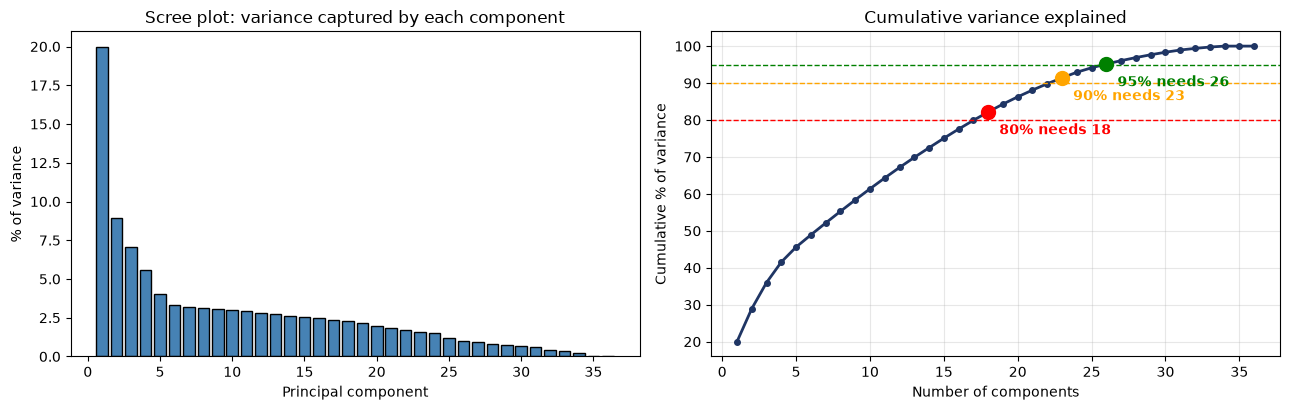

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

n = len(ev)
ax[0].bar(range(1, n+1), ev*100, color='steelblue', edgecolor='black')
ax[0].set_xlabel('Principal component')
ax[0].set_ylabel('% of variance')
ax[0].set_title('Scree plot: variance captured by each component')

ax[1].plot(range(1, n+1), cum*100, 'o-', color='#1F3564', lw=2, ms=4)
for t, col in [(80, 'red'), (90, 'orange'), (95, 'green')]:
    k = int(np.argmax(cum >= t/100) + 1)
    ax[1].axhline(t, color=col, ls='--', lw=1)
    ax[1].plot([k], [cum[k-1]*100], 'o', color=col, ms=10)
    ax[1].annotate(f'{t}% needs {k}', (k, cum[k-1]*100),
                   textcoords='offset points', xytext=(8, -16),
                   color=col, fontweight='bold', fontsize=10)
ax[1].set_xlabel('Number of components')
ax[1].set_ylabel('Cumulative % of variance')
ax[1].set_title('Cumulative variance explained')
ax[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

In [12]:
print('THE FOUR RULES, applied to your data')
print('=' * 52)

for t in [0.80, 0.90, 0.95, 0.99]:
    k = int(np.argmax(cum >= t) + 1)
    print(f'  {int(t*100)}% of variance      : keep {k:>2} of {n} components  '
          f'({k/n*100:.0f}% of the original width)')

kaiser = int((pca.explained_variance_ > 1).sum())
print(f'  Kaiser rule (eig > 1) : keep {kaiser:>2} of {n} components')
print(f'  Just two (for a plot) : keep  2 of {n} components  '
      f'({cum[1]*100:.1f}% of variance)')
print()
print('Different rules, different answers. Pick one, state it, defend it.')

THE FOUR RULES, applied to your data
  80% of variance      : keep 18 of 36 components  (50% of the original width)
  90% of variance      : keep 23 of 36 components  (64% of the original width)
  95% of variance      : keep 26 of 36 components  (72% of the original width)
  99% of variance      : keep 32 of 36 components  (89% of the original width)
  Kaiser rule (eig > 1) : keep 12 of 36 components
  Just two (for a plot) : keep  2 of 36 components  (28.9% of variance)

Different rules, different answers. Pick one, state it, defend it.


In [13]:
# The elbow: where does the drop stop being steep?
drop = -np.diff(ev)          # how much each component falls from the one before
elbow = int(np.argmax(drop < drop.mean() * 0.25) + 1)

print('Variance drop from one component to the next:')
for i in range(min(8, len(drop))):
    print(f'  PC{i+1} -> PC{i+2} : {drop[i]*100:>6.2f} percentage points')
print()
print(f'The curve flattens out around component {elbow}.')
print('This is a judgement call. Two analysts will disagree. Say which you chose.')

Variance drop from one component to the next:
  PC1 -> PC2 :  11.04 percentage points
  PC2 -> PC3 :   1.87 percentage points
  PC3 -> PC4 :   1.52 percentage points
  PC4 -> PC5 :   1.50 percentage points
  PC5 -> PC6 :   0.75 percentage points
  PC6 -> PC7 :   0.09 percentage points
  PC7 -> PC8 :   0.06 percentage points
  PC8 -> PC9 :   0.06 percentage points

The curve flattens out around component 6.
This is a judgement call. Two analysts will disagree. Say which you chose.


---
# Section 4: Reading the Loadings

A component is a weighted mix of your original columns. The weights are the loadings.
This is the only way to make a component mean something.

In [14]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f'PC{i+1}' for i in range(len(ev))])

print('PC1 is built like this. Largest contributors first:')
pc1 = loadings['PC1'].sort_values(key=abs, ascending=False).head(10)
print(pc1.round(3).to_string())

PC1 is built like this. Largest contributors first:
Gr Liv Area      0.297
Overall Qual     0.296
Garage Cars      0.285
Garage Area      0.280
Total Bsmt SF    0.258
1st Flr SF       0.258
Full Bath        0.256
Year Built       0.246
TotRms AbvGrd    0.230
Garage Yr Blt    0.230


In [15]:
def show_pc(k, top=8):
    s = loadings[f'PC{k}'].sort_values(key=abs, ascending=False).head(top)
    print(f'--- PC{k}  ({ev[k-1]*100:.1f}% of variance) ---')
    for name, v in s.items():
        bar = '#' * int(abs(v) * 40)
        sign = '+' if v > 0 else '-'
        print(f'  {sign} {name:22s} {v:>7.3f}  {bar}')
    print()

for k in [1, 2, 3]:
    show_pc(k)

--- PC1  (20.0% of variance) ---
  + Gr Liv Area              0.297  ###########
  + Overall Qual             0.296  ###########
  + Garage Cars              0.285  ###########
  + Garage Area              0.280  ###########
  + Total Bsmt SF            0.258  ##########
  + 1st Flr SF               0.258  ##########
  + Full Bath                0.256  ##########
  + Year Built               0.246  #########

--- PC2  (8.9% of variance) ---
  + 2nd Flr SF               0.436  #################
  + Bedroom AbvGr            0.365  ##############
  + TotRms AbvGrd            0.325  #############
  - BsmtFin SF 1            -0.311  ############
  - Bsmt Full Bath          -0.292  ###########
  + Gr Liv Area              0.244  #########
  + Half Bath                0.241  #########
  - Total Bsmt SF           -0.213  ########

--- PC3  (7.1% of variance) ---
  + Garage Yr Blt            0.355  ##############
  + Year Built               0.335  #############
  - Lot Frontage            -0.3

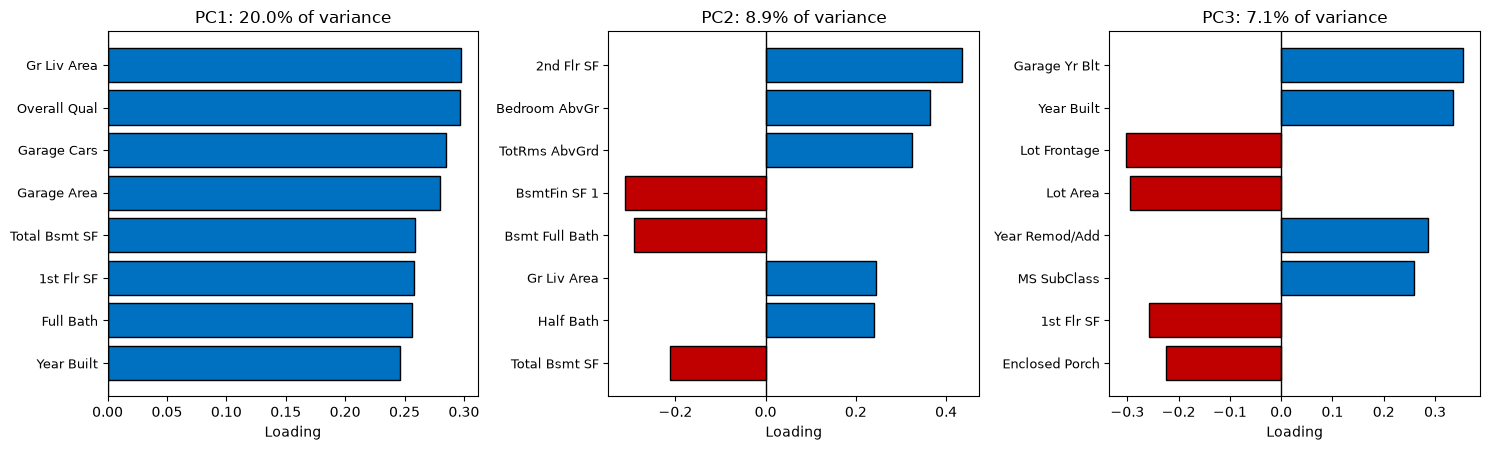

In [16]:
# Same thing as a picture, for the slides
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for i, k in enumerate([1, 2, 3]):
    s = loadings[f'PC{k}'].sort_values(key=abs, ascending=False).head(8)
    s = s.iloc[::-1]
    cols = ['#C00000' if v < 0 else '#0070C0' for v in s]
    ax[i].barh(range(len(s)), s.values, color=cols, edgecolor='black')
    ax[i].set_yticks(range(len(s)))
    ax[i].set_yticklabels(s.index, fontsize=9)
    ax[i].axvline(0, color='black', lw=1)
    ax[i].set_title(f'PC{k}: {ev[k-1]*100:.1f}% of variance')
    ax[i].set_xlabel('Loading')
plt.tight_layout()
plt.show()

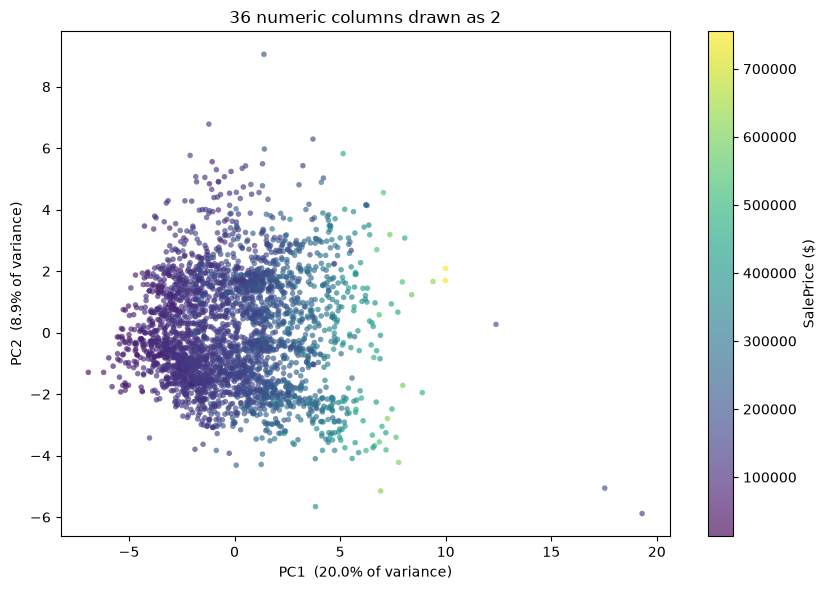

PCA never saw SalePrice. The colour gradient came out of the other columns.
You are looking at 28.9% of the information. The rest is invisible here.


In [17]:
# A picture of the houses on PC1 and PC2, coloured by price
plt.figure(figsize=(8.5, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap='viridis',
                 s=16, alpha=.65, edgecolors='none')
plt.colorbar(sc, label='SalePrice ($)')
plt.xlabel(f'PC1  ({ev[0]*100:.1f}% of variance)')
plt.ylabel(f'PC2  ({ev[1]*100:.1f}% of variance)')
plt.title(f'{X.shape[1]} numeric columns drawn as 2')
plt.tight_layout()
plt.show()

print('PCA never saw SalePrice. The colour gradient came out of the other columns.')
print(f'You are looking at {cum[1]*100:.1f}% of the information. The rest is invisible here.')

---
# Section 5: Scaling is Not Optional

Run PCA on the same data without standardizing, and watch what happens.

In [18]:
pca_raw = PCA().fit(X)          # NOT scaled
ev_raw  = pca_raw.explained_variance_ratio_

print(f"{'PC':>5}{'NOT scaled':>14}{'scaled':>12}")
print('-' * 31)
for i in range(6):
    print(f'{i+1:>5}{ev_raw[i]*100:>13.4f}%{ev[i]*100:>11.2f}%')
print()
print(f'NOT scaled, PC1 alone : {ev_raw[0]*100:.2f}% of variance')
print(f'Scaled,     PC1 alone : {ev[0]*100:.2f}% of variance')

   PC    NOT scaled      scaled
-------------------------------
    1      97.5100%      19.98%
    2       0.7607%       8.94%
    3       0.5416%       7.07%
    4       0.4868%       5.55%
    5       0.4246%       4.05%
    6       0.0870%       3.30%

NOT scaled, PC1 alone : 97.51% of variance
Scaled,     PC1 alone : 19.98% of variance


In [19]:
# Which column is unscaled PC1 actually measuring?
raw_l = pd.Series(pca_raw.components_[0], index=X.columns)
print('Unscaled PC1, largest loadings:')
print(raw_l.sort_values(key=abs, ascending=False).head(5).round(4).to_string())
print()
print('Compare against the raw spread of those columns:')
print(X.std().sort_values(ascending=False).head(5).round(1).to_string())
print()
print('Same columns. Unscaled PC1 is just the column with the biggest numbers.')

Unscaled PC1, largest loadings:
Lot Area         0.9995
Gr Liv Area      0.0184
1st Flr SF       0.0166
Total Bsmt SF    0.0143
BsmtFin SF 1     0.0112

Compare against the raw spread of those columns:
Lot Area         7880.0
Misc Val          566.3
Gr Liv Area       505.5
BsmtFin SF 1      455.5
Total Bsmt SF     440.5

Same columns. Unscaled PC1 is just the column with the biggest numbers.


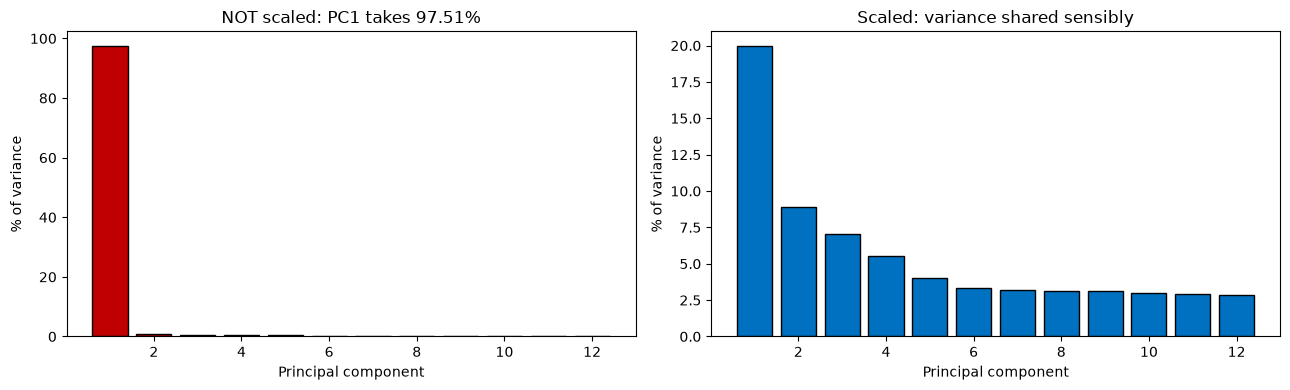

A student who skipped scaling would report "one component explains almost
everything" and think it was a brilliant result. It is not a result at all.


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 13), ev_raw[:12]*100, color='#C00000', edgecolor='black')
ax[0].set_title(f'NOT scaled: PC1 takes {ev_raw[0]*100:.2f}%')
ax[0].set_xlabel('Principal component'); ax[0].set_ylabel('% of variance')
ax[1].bar(range(1, 13), ev[:12]*100, color='#0070C0', edgecolor='black')
ax[1].set_title('Scaled: variance shared sensibly')
ax[1].set_xlabel('Principal component'); ax[1].set_ylabel('% of variance')
plt.tight_layout(); plt.show()

print('A student who skipped scaling would report "one component explains almost')
print('everything" and think it was a brilliant result. It is not a result at all.')

---
# Section 6: PCA on All 285 Encoded Columns

Now the messy version. Encode everything and run PCA on the lot.

In [21]:
full = pd.get_dummies(df.drop(columns=[c for c in DROP if c in df.columns]))
full = full.fillna(full.median(numeric_only=True))
y_full = full.pop('SalePrice')

print('Encoded shape:', full.shape)
print(f'Zeros in the matrix: {(full == 0).mean().mean()*100:.1f} % of all cells')

Encoded shape: (2930, 303)
Zeros in the matrix: 79.5 % of all cells


In [22]:
Xf = StandardScaler().fit_transform(full)
pf = PCA().fit(Xf)
evf  = pf.explained_variance_ratio_
cumf = np.cumsum(evf)

print(f"{'':26s}{'numeric only':>15}{'all encoded':>15}")
print('-' * 56)
print(f"{'columns in':26s}{X.shape[1]:>15}{full.shape[1]:>15}")
print(f"{'PC1 variance':26s}{ev[0]*100:>14.1f}%{evf[0]*100:>14.1f}%")
print(f"{'PC1+PC2 variance':26s}{cum[1]*100:>14.1f}%{cumf[1]*100:>14.1f}%")
for t in [.80, .95]:
    a = int(np.argmax(cum  >= t) + 1)
    b = int(np.argmax(cumf >= t) + 1)
    print(f"{f'components for {int(t*100)}%':26s}{a:>15}{b:>15}")

                             numeric only    all encoded
--------------------------------------------------------
columns in                             36            303
PC1 variance                        20.0%           6.1%
PC1+PC2 variance                    28.9%           8.8%
components for 80%                     18            134
components for 95%                     26            202


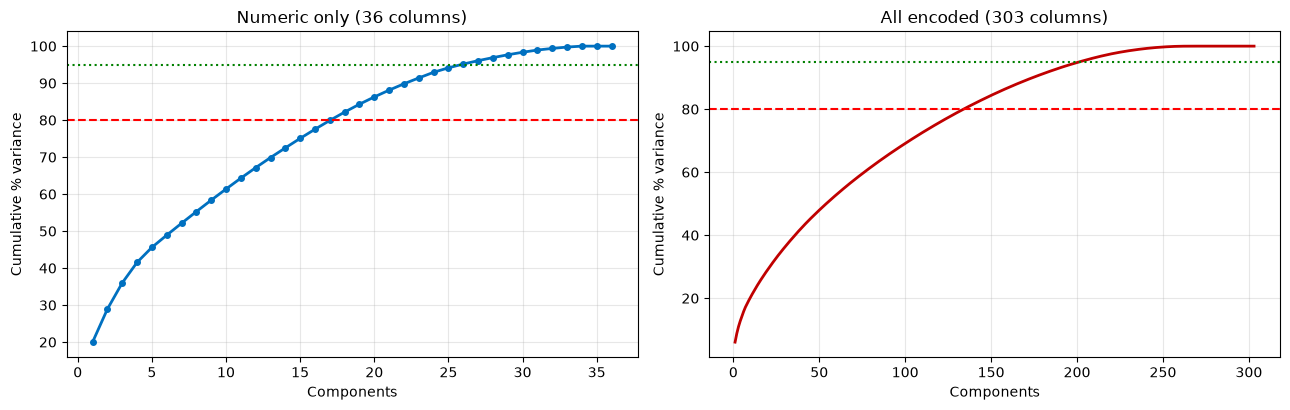

Left curve rises fast then flattens. There is a real elbow.
Right curve climbs slowly and steadily. No elbow. That is what sparse data does.


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(range(1, len(cum)+1), cum*100, 'o-', lw=2, ms=4, color='#0070C0')
ax[0].axhline(80, color='red', ls='--'); ax[0].axhline(95, color='green', ls=':')
ax[0].set_title(f'Numeric only ({X.shape[1]} columns)')
ax[0].set_xlabel('Components'); ax[0].set_ylabel('Cumulative % variance'); ax[0].grid(alpha=.3)

ax[1].plot(range(1, len(cumf)+1), cumf*100, '-', lw=2, color='#C00000')
ax[1].axhline(80, color='red', ls='--'); ax[1].axhline(95, color='green', ls=':')
ax[1].set_title(f'All encoded ({full.shape[1]} columns)')
ax[1].set_xlabel('Components'); ax[1].set_ylabel('Cumulative % variance'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print('Left curve rises fast then flattens. There is a real elbow.')
print('Right curve climbs slowly and steadily. No elbow. That is what sparse data does.')

### What this tells you

PCA works on one-hot data, but it works less well:

- Variance spreads across far more components. No clean elbow.
- Early components tend to be dominated by whichever categorical column had the
  most categories.
- Loadings mix hundreds of columns, so naming them is much harder.

---
# Section 7: Feature Selection, Filter Methods

The other answer. Instead of building new columns, delete the ones that do not help.

## 7.1 Drop near-constant columns

If almost every row has the same value, the column cannot separate anything.

In [24]:
from sklearn.feature_selection import VarianceThreshold

frac = (full == 0).mean().sort_values(ascending=False)
print('Columns that are 99% or more zeros:')
near_const = frac[frac >= 0.99]
print(f'   count: {len(near_const)} of {full.shape[1]}')
print()
print(near_const.head(10).round(4).to_string())

Columns that are 99% or more zeros:
   count: 104 of 303

Kitchen Qual_Po         0.9997
Roof Matl_ClyTile       0.9997
Exterior 2nd_Other      0.9997
Exterior 2nd_PreCast    0.9997
Misc Feature_Elev       0.9997
Mas Vnr Type_CBlock     0.9997
Misc Feature_TenC       0.9997
Roof Matl_Roll          0.9997
Roof Matl_Metal         0.9997
Exterior 1st_PreCast    0.9997


In [25]:
vt = VarianceThreshold(threshold=0.01)
vt.fit(full)
kept_vt = full.columns[vt.get_support()]

print(f'Columns before : {full.shape[1]}')
print(f'Columns after  : {len(kept_vt)}')
print(f'Dropped        : {full.shape[1] - len(kept_vt)}')
print()
print('Examples of what got dropped:')
print(list(full.columns[~vt.get_support()])[:12])

Columns before : 303
Columns after  : 198
Dropped        : 105

Examples of what got dropped:
['MS Zoning_A (agr)', 'MS Zoning_C (all)', 'MS Zoning_I (all)', 'MS Zoning_RH', 'Street_Grvl', 'Street_Pave', 'Lot Shape_IR3', 'Utilities_AllPub', 'Utilities_NoSeWa', 'Utilities_NoSewr', 'Lot Config_FR3', 'Land Slope_Sev']


## 7.2 Drop one of every highly correlated pair

Two columns correlating at 0.9 carry the same information twice.

In [26]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = (upper.stack()
              .sort_values(ascending=False)
              .head(15)
              .reset_index())
pairs.columns = ['column A', 'column B', 'correlation']
print('Most correlated pairs among the numeric columns:')
print(pairs.round(3).to_string(index=False))

Most correlated pairs among the numeric columns:
      column A       column B  correlation
   Garage Cars    Garage Area        0.890
   Gr Liv Area  TotRms AbvGrd        0.808
 Total Bsmt SF     1st Flr SF        0.801
    Year Built  Garage Yr Blt        0.788
 Bedroom AbvGr  TotRms AbvGrd        0.673
    2nd Flr SF    Gr Liv Area        0.655
  BsmtFin SF 1 Bsmt Full Bath        0.640
   Gr Liv Area      Full Bath        0.630
Year Remod/Add  Garage Yr Blt        0.626
    Year Built Year Remod/Add        0.612
    2nd Flr SF      Half Bath        0.612
  Overall Qual    Garage Cars        0.599
  Overall Qual     Year Built        0.597
    2nd Flr SF  TotRms AbvGrd        0.585
  Overall Qual    Gr Liv Area        0.571


In [27]:
THRESHOLD = 0.80
to_drop = [c for c in upper.columns if any(upper[c] > THRESHOLD)]

print(f'Correlation threshold : {THRESHOLD}')
print(f'Columns before        : {X.shape[1]}')
print(f'Columns to drop       : {len(to_drop)}')
print(f'Columns after         : {X.shape[1] - len(to_drop)}')
print()
print('Dropped:', to_drop)

X_decorr = X.drop(columns=to_drop)

Correlation threshold : 0.8
Columns before        : 36
Columns to drop       : 3
Columns after         : 33

Dropped: ['1st Flr SF', 'TotRms AbvGrd', 'Garage Area']


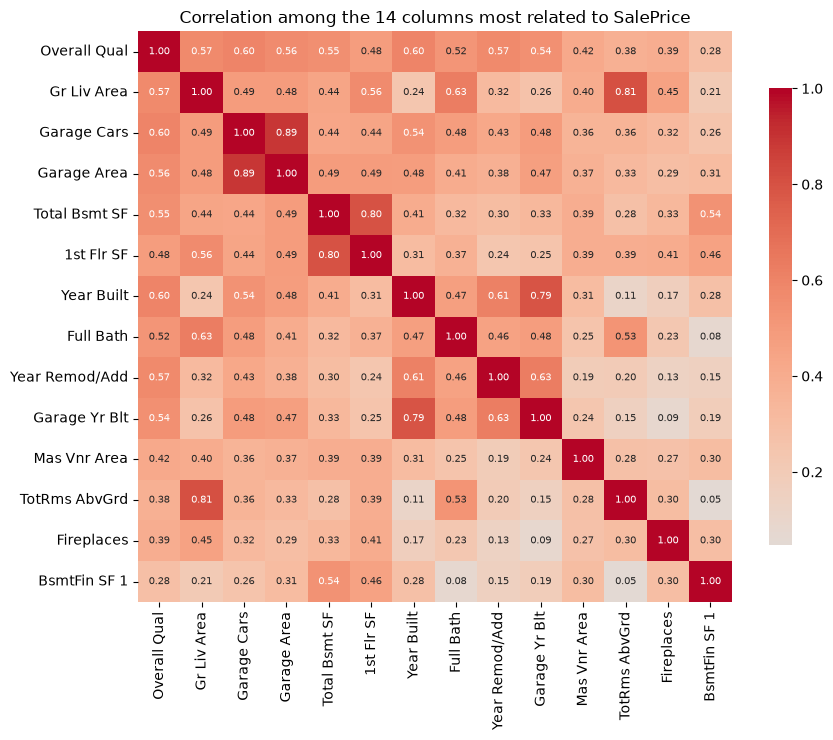

Look for the dark red squares off the diagonal. Those are your duplicates.


In [28]:
# Picture of the correlation structure
plt.figure(figsize=(9, 7.5))
top = X.corrwith(y).abs().sort_values(ascending=False).head(14).index
sns.heatmap(X[top].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, annot_kws={'size': 7}, cbar_kws={'shrink': .8})
plt.title('Correlation among the 14 columns most related to SalePrice')
plt.tight_layout(); plt.show()

print('Look for the dark red squares off the diagonal. Those are your duplicates.')

## 7.3 Rank by relationship with the target

The first two methods never looked at what you are predicting. This one does.

In [29]:
rel = X.corrwith(y).abs().sort_values(ascending=False)

print('Most related to SalePrice:')
print(rel.head(15).round(3).to_string())
print()
print('Least related (candidates to drop):')
print(rel.tail(8).round(3).to_string())

Most related to SalePrice:
Overall Qual      0.799
Gr Liv Area       0.707
Garage Cars       0.648
Garage Area       0.640
Total Bsmt SF     0.632
1st Flr SF        0.622
Year Built        0.558
Full Bath         0.546
Year Remod/Add    0.533
Garage Yr Blt     0.509
Mas Vnr Area      0.502
TotRms AbvGrd     0.495
Fireplaces        0.475
BsmtFin SF 1      0.433
Lot Frontage      0.340

Least related (candidates to drop):
Pool Area          0.068
Low Qual Fin SF    0.038
Bsmt Half Bath     0.036
Mo Sold            0.035
3Ssn Porch         0.032
Yr Sold            0.031
Misc Val           0.016
BsmtFin SF 2       0.006


In [30]:
from sklearn.feature_selection import SelectKBest, f_regression

K = 15
sel = SelectKBest(score_func=f_regression, k=K).fit(X, y)
kept = X.columns[sel.get_support()].tolist()

print(f'SelectKBest kept these {K} columns:')
for c in kept:
    print(f'   {c:22s} corr with SalePrice = {rel[c]:.3f}')

SelectKBest kept these 15 columns:
   Lot Frontage           corr with SalePrice = 0.340
   Overall Qual           corr with SalePrice = 0.799
   Year Built             corr with SalePrice = 0.558
   Year Remod/Add         corr with SalePrice = 0.533
   Mas Vnr Area           corr with SalePrice = 0.502
   BsmtFin SF 1           corr with SalePrice = 0.433
   Total Bsmt SF          corr with SalePrice = 0.632
   1st Flr SF             corr with SalePrice = 0.622
   Gr Liv Area            corr with SalePrice = 0.707
   Full Bath              corr with SalePrice = 0.546
   TotRms AbvGrd          corr with SalePrice = 0.495
   Fireplaces             corr with SalePrice = 0.475
   Garage Yr Blt          corr with SalePrice = 0.509
   Garage Cars            corr with SalePrice = 0.648
   Garage Area            corr with SalePrice = 0.640


### The warning that matters

All three of these judge columns **one at a time**.

Two columns that are individually useless can be powerful together. A filter method
will never see that, and will throw both away.

That is exactly what wrapper and embedded methods catch, and filters cannot.

In [31]:
# Embedded method, for contrast. The model selects while it trains.
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=120, random_state=0, n_jobs=-1)
rf.fit(X, y)

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print('Random forest feature importance, top 15:')
print(imp.head(15).round(4).to_string())
print()
overlap = set(imp.head(15).index) & set(kept)
print(f'Overlap with the correlation-based top 15: {len(overlap)} of 15')
print()
print('The two methods disagree. Correlation sees straight lines only.')
print('The forest can see interactions and curves.')

Random forest feature importance, top 15:
Overall Qual      0.6421
Gr Liv Area       0.1106
Total Bsmt SF     0.0419
1st Flr SF        0.0340
BsmtFin SF 1      0.0219
2nd Flr SF        0.0180
Lot Area          0.0164
Year Built        0.0122
Garage Area       0.0119
Garage Cars       0.0115
Year Remod/Add    0.0103
Full Bath         0.0083
Lot Frontage      0.0081
Open Porch SF     0.0059
Bsmt Unf SF       0.0052

Overlap with the correlation-based top 15: 11 of 15

The two methods disagree. Correlation sees straight lines only.
The forest can see interactions and curves.


---
# Section 8: PCA vs Feature Selection, Head to Head

Same model, same target, four different sets of inputs.

In [32]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

def score(Xin, label):
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    s = cross_val_score(pipe, Xin, y, cv=5, scoring='r2')
    print(f'{label:38s} cols={Xin.shape[1]:>4}   R2 = {s.mean():.4f}  (+/- {s.std():.4f})')
    return s.mean()

print('5-fold cross validated R-squared. Higher is better.')
print('=' * 74)

r_all   = score(X, 'All numeric columns')
r_sel   = score(X[kept], f'Feature selection, top {K} by correlation')
r_rf    = score(X[imp.head(K).index.tolist()], f'Feature selection, top {K} by forest')
r_decor = score(X_decorr, 'Correlated pairs removed')

k80 = int(np.argmax(cum >= .80) + 1)
k95 = int(np.argmax(cum >= .95) + 1)
r_p80 = score(pd.DataFrame(Z[:, :k80]), f'PCA, {k80} components (80% variance)')
r_p95 = score(pd.DataFrame(Z[:, :k95]), f'PCA, {k95} components (95% variance)')
r_p2  = score(pd.DataFrame(Z[:, :2]),   'PCA, 2 components (for plotting)')

5-fold cross validated R-squared. Higher is better.
All numeric columns                    cols=  36   R2 = 0.8102  (+/- 0.0682)
Feature selection, top 15 by correlation cols=  15   R2 = 0.8011  (+/- 0.0596)
Feature selection, top 15 by forest    cols=  15   R2 = 0.7964  (+/- 0.0614)
Correlated pairs removed               cols=  33   R2 = 0.8102  (+/- 0.0668)
PCA, 18 components (80% variance)      cols=  18   R2 = 0.7915  (+/- 0.0606)
PCA, 26 components (95% variance)      cols=  26   R2 = 0.7963  (+/- 0.0708)
PCA, 2 components (for plotting)       cols=   2   R2 = 0.7635  (+/- 0.0560)


In [33]:
results = pd.DataFrame({
    'approach': ['All numeric', f'Top {K} by correlation', f'Top {K} by forest',
                 'Correlated pairs removed', f'PCA {k80} comp', f'PCA {k95} comp', 'PCA 2 comp'],
    'columns' : [X.shape[1], K, K, X_decorr.shape[1], k80, k95, 2],
    'R2'      : [r_all, r_sel, r_rf, r_decor, r_p80, r_p95, r_p2],
})
results['vs all columns'] = (results['R2'] - r_all).round(4)
print(results.round(4).to_string(index=False))

                approach  columns     R2  vs all columns
             All numeric       36 0.8102          0.0000
   Top 15 by correlation       15 0.8011         -0.0090
        Top 15 by forest       15 0.7964         -0.0138
Correlated pairs removed       33 0.8102          0.0001
             PCA 18 comp       18 0.7915         -0.0186
             PCA 26 comp       26 0.7963         -0.0139
              PCA 2 comp        2 0.7635         -0.0467


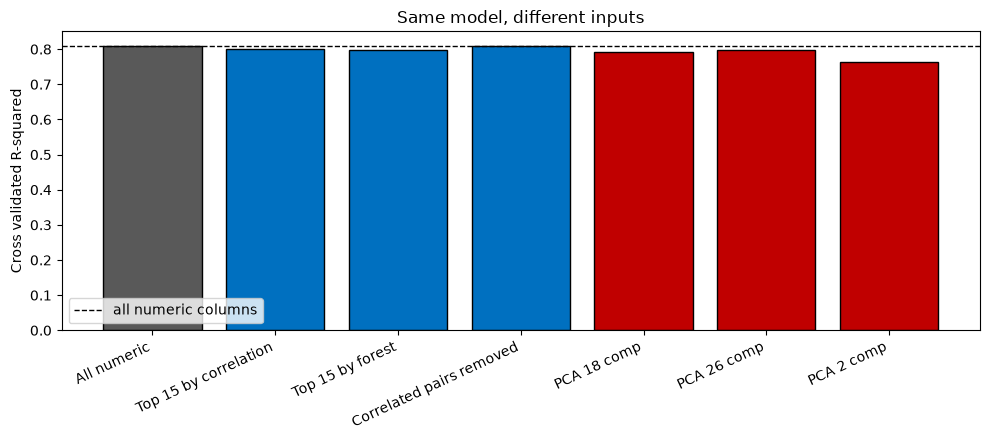

Blue = feature selection. Red = PCA. Grey = no reduction.


In [34]:
plt.figure(figsize=(10, 4.5))
colors = ['#595959'] + ['#0070C0']*3 + ['#C00000']*3
plt.bar(results['approach'], results['R2'], color=colors, edgecolor='black')
plt.axhline(r_all, color='black', ls='--', lw=1, label='all numeric columns')
plt.ylabel('Cross validated R-squared')
plt.title('Same model, different inputs')
plt.xticks(rotation=25, ha='right')
plt.legend(); plt.tight_layout(); plt.show()

print('Blue = feature selection. Red = PCA. Grey = no reduction.')